# Learning module 16 — Extract reusable native UI operations

**Small milestone:** separate three operations from the movie-specific exercises: observe the UI, inspect a unique element, and issue one guarded tap. Keep them in this notebook and verify observation/inspection on the real app. The tap wrapper is defined and its guards are checked offline; this exercise does not tap the live app.

| Function | Input supplied by trusted caller | Structured result |
| --- | --- | --- |
| `observe_ui` | Live driver and artifact directory | XML/PNG paths, capture times, complete/partial/failed status, recording errors. |
| `inspect_element` | Live driver and an observed accessibility identifier | Missing/ambiguous/resolved/unavailable status, match count, native attributes. |
| `tap_element` | Live driver, observed identifier, artifact directory, optional expected native type | Rejected/acknowledged/uncertain receipt, guarded target, dispatch intent and response facts. |

These are ordinary Python functions. There is no `@tool`, MCP server, LLM, classifier, or LangGraph node yet. When tools are registered later, the backend will bind the driver and artifact directory; those host objects/paths should not become model-chosen parameters. Public results contain JSON-compatible values, not a `WebElement` or driver handle.

The helpers contain no Movies selectors or title/year assertions. Domain-neutral does not mean every platform is implemented: inspection currently uses native iOS attributes (`type`, `name`, `label`), so Android/web adapters will need their own mappings. The existing movie analyzer stays separate.

### Boundaries that matter

- The caller creates and closes the session and owns process cleanup and transport timeouts/retry settings.
- A session ID is recorded for correlation; its presence alone does not prove the remote session is alive. A closed/lost session is reported through the driver error.
- Inspection does not change the app. `tap_element` reacquires the identifier and checks the same unique native element immediately before clicking; it never accepts a previously cached element handle.
- Acknowledged means the click command returned successfully. It does not verify navigation or a business assertion. If dispatch raises, the result is uncertain and is not automatically retried.
- Tap intent must be recorded before dispatch. A recording failure blocks the click. Returned `receipt_persisted` explicitly distinguishes a saved receipt from a failed recording attempt.
- XML and PNG are attempted independently. An available artifact survives failure of the other capture, and the receipt records validity/errors.

These rules carry forward the behavior learned in modules 12–15. XML attributes can be merged, names can fall back to labels, and an identifier is not guaranteed to be a parent container. The helpers leave those observations for the caller/analyzer to interpret.


The intermediate saved tap receipt is `dispatch_pending`. If a process stops before its final acknowledgment is recorded, that pending intent must be reconciled with new evidence; it is not proof that the action did not happen.


Receipt updates use a temporary file in the same directory followed by atomic replacement. If the final update fails after a click, the earlier valid pending receipt remains available; the returned result separately reports that the final receipt was not saved. This is a local recording boundary, not a distributed transaction or an exactly-once guarantee.


## This notebook

Part **16 — Reusable capture, inspection, and tap primitives** of the learning sequence. [Notebook index](README.md).

Select the project's `.venv` Python kernel and run this notebook from top to bottom. Its Python setup is included locally; running another notebook in another kernel does not populate this one's variables or PATH. The supported working directories are the project root, `server/`, and `server/sample_scenarios/`.

**Execution scope:** Live demo observes/inspects only; tap wrapper is not dispatched.

Saved lesson outputs and embedded screenshots are historical snapshots preserved during the split on November 3, 2026. Newly included setup cells have no saved outputs. Rerunning an executable scenario creates fresh local artifacts; these continue living in `server/.tools/`, not beside the notebooks.

### Setup for this notebook

These source-only prerequisite cells are repeated intentionally so the lesson is runnable in a fresh kernel. They configure local values/environment and inspect tool versions; they do not launch an Appium server, create a session, or tap/type in the app. The original lessons remain linked for explanation.


In [1]:
# Setup: Sample scenario input (lesson 01)
from pprint import pprint

scenario_text = (
    "In Movies, search for Interstellar, open the 2014 movie, "
    "and verify that its details show the title Interstellar "
    "and release year 2014."
)

scenario_input = {
    "instruction": scenario_text,
    "application_name": "Movies",
    "application_profile_ref": None,
    "requested_actions": [
        "search_for_movie",
        "open_matching_movie_details",
    ],
    "search_query": "Interstellar",
    "target_item_identity": {"title": "Interstellar", "release_year": 2014},
    "expected_title": "Interstellar",
    "expected_release_year": 2014,
    "title_matching_rule": "exact",  # Proposed comparison rule for this exercise.
}

pprint(scenario_input, sort_dicts=False)


{'instruction': 'In Movies, search for Interstellar, open the 2014 movie, and '
                'verify that its details show the title Interstellar and '
                'release year 2014.',
 'application_name': 'Movies',
 'application_profile_ref': None,
 'requested_actions': ['search_for_movie', 'open_matching_movie_details'],
 'search_query': 'Interstellar',
 'target_item_identity': {'title': 'Interstellar', 'release_year': 2014},
 'expected_title': 'Interstellar',
 'expected_release_year': 2014,
 'title_matching_rule': 'exact'}


In [2]:
# Setup: Recorded run profile (lesson 03)
from pprint import pprint

run_profile = {
    "id": "movies-ios-local",
    "platform": "ios",
    "execution_provider": "local",
    "app_bundle_id": "com.example.movies",
    "simulator_udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
}

app_profiles = {run_profile["id"]: run_profile}
scenario_input["application_profile_ref"] = run_profile["id"]
selected_profile = app_profiles[scenario_input["application_profile_ref"]]

print("Scenario profile reference:", scenario_input["application_profile_ref"])
pprint(selected_profile, sort_dicts=False)


Scenario profile reference: movies-ios-local
{'id': 'movies-ios-local',
 'platform': 'ios',
 'execution_provider': 'local',
 'app_bundle_id': 'com.example.movies',
 'simulator_udid': '4F0707AE-45BC-464D-9099-6EE76C3740A9'}


In [3]:
# Setup: Local Node activation (lesson 05)
import os
from pathlib import Path
import shutil
import subprocess

notebook_cwd = Path.cwd().resolve()
server_candidates = (notebook_cwd, notebook_cwd / "server", *notebook_cwd.parents)
server_dir = next((candidate for candidate in server_candidates
                   if (candidate / ".node-version").is_file()
                   and (candidate / "package.json").is_file()
                   and (candidate / "sample_scenarios").is_dir()), None)
if server_dir is None:
    raise RuntimeError("Run from the project root, server, or sample_scenarios folder.")

node_version = (server_dir / ".node-version").read_text().strip()
node_bin = server_dir / ".tools" / f"node-v{node_version}-darwin-arm64" / "bin"
if not (node_bin / "node").is_file():
    raise FileNotFoundError(f"Project-local Node is missing: {node_bin}")

path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(node_bin)]
os.environ["PATH"] = os.pathsep.join([str(node_bin), *path_entries])

print("Selected Node:", shutil.which("node"))
print("Node version:", subprocess.check_output(["node", "--version"], text=True, timeout=10).strip())
print("npm version:", subprocess.check_output(["npm", "--version"], text=True, timeout=10).strip())


Selected Node: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/node-v24.22.2-darwin-arm64/bin/node
Node version: v24.22.2
npm version: 11.19.1


In [4]:
# Setup: Local Appium activation (lesson 06)
import json
import os
import shutil
import subprocess

if "server_dir" not in globals() or "node_bin" not in globals():
    raise RuntimeError("Run the Node setup cell in this notebook first.")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime first.")

appium_bin_dir = server_dir / "node_modules" / ".bin"
appium_executable = appium_bin_dir / "appium"
if not appium_executable.is_file():
    raise FileNotFoundError("The project-local Appium package is missing.")

os.environ["APPIUM_HOME"] = str(server_dir / ".tools" / "appium")
os.environ["npm_config_cache"] = str(server_dir / ".tools" / "npm-cache")
path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(appium_bin_dir)]
os.environ["PATH"] = os.pathsep.join([str(appium_bin_dir), *path_entries])

expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
actual_version = subprocess.check_output(
    [str(appium_executable), "--version"], cwd=server_dir, text=True, timeout=30
).strip()
if actual_version != expected_version:
    raise RuntimeError(f"Expected Appium {expected_version}, found {actual_version}.")

print("Selected Appium:", shutil.which("appium"))
print("Appium version:", actual_version)
print("Appium home:", os.environ["APPIUM_HOME"])


Selected Appium: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/node_modules/.bin/appium
Appium version: 3.9.0
Appium home: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium


dbug Appium Creating hash file directory: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium/node_modules/.cache/appium


In [5]:
# Setup: Local iOS options (lesson 09)
import json
from appium.options.ios import XCUITestOptions

if "selected_profile" not in globals():
    raise RuntimeError("Run the scenario/profile setup cells in this notebook first.")
if selected_profile.get("platform") != "ios":
    raise ValueError("This example requires an iOS run profile.")
for field in ["app_bundle_id", "simulator_udid"]:
    value = selected_profile.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The selected profile needs a nonempty {field}.")

ios_options = XCUITestOptions()
ios_options.udid = selected_profile["simulator_udid"]
ios_options.bundle_id = selected_profile["app_bundle_id"]
ios_options.no_reset = True
ios_options.full_reset = False

session_request = ios_options.to_w3c()
print(json.dumps(session_request, indent=2))


{
  "capabilities": {
    "firstMatch": [
      {}
    ],
    "alwaysMatch": {
      "appium:automationName": "XCUITest",
      "platformName": "iOS",
      "appium:udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
      "appium:bundleId": "com.example.movies",
      "appium:noReset": true,
      "appium:fullReset": false
    }
  }
}


In [6]:
import json
from pathlib import Path
from datetime import datetime, timezone
import tempfile
import xml.etree.ElementTree as ET
from appium.webdriver.common.appiumby import AppiumBy


def _ui_receipt(driver, operation):
    return {"operation": operation, "session_id": driver.session_id,
            "started_at": datetime.now(timezone.utc).isoformat(), "errors": []}


def _record_error(receipt, stage, error):
    receipt["errors"].append({"stage": stage, "type": type(error).__name__, "message": str(error)})


def _receipt_folder(artifact_root, prefix):
    root = Path(artifact_root)
    root.mkdir(parents=True, exist_ok=True)
    return Path(tempfile.mkdtemp(prefix=prefix, dir=root))


def _persist_ui_receipt(receipt):
    receipt["receipt_persisted"] = True
    receipt["recorded_at"] = datetime.now(timezone.utc).isoformat()
    temporary_path = None
    try:
        destination = Path(receipt["manifest_path"])
        with tempfile.NamedTemporaryFile(dir=destination.parent, prefix=".receipt-", suffix=".tmp",
                                         delete=False) as temporary:
            temporary_path = Path(temporary.name)
        temporary_path.write_text(json.dumps(receipt, indent=2), encoding="utf-8")
        temporary_path.replace(destination)  # Atomic update keeps an earlier valid intent on write failure.
        return True
    except OSError as error:
        receipt["receipt_persisted"] = False
        _record_error(receipt, "record_receipt", error)
        return False
    finally:
        if temporary_path is not None:
            try:
                temporary_path.unlink(missing_ok=True)
            except OSError:
                pass  # Do not replace the operation/recording error with temporary-file cleanup.


def observe_ui(driver, artifact_root):
    receipt = _ui_receipt(driver, "observe_ui")
    receipt.update(status="failed", artifacts={}, receipt_persisted=False)
    try:
        folder = _receipt_folder(artifact_root, "observe-")
    except OSError as error:
        _record_error(receipt, "create_artifact_folder", error)
        return receipt
    receipt["manifest_path"] = str(folder / "manifest.json")
    try:
        started = datetime.now(timezone.utc).isoformat()
        xml_text = driver.page_source
        completed = datetime.now(timezone.utc).isoformat()
        path = folder / "hierarchy.xml"
        path.write_text(xml_text, encoding="utf-8")
        receipt["artifacts"]["hierarchy"] = {
            "path": str(path), "started_at": started, "completed_at": completed, "valid": False,
        }
        ET.fromstring(xml_text)
        receipt["artifacts"]["hierarchy"]["valid"] = True
    except Exception as error:
        _record_error(receipt, "capture_hierarchy", error)
    try:
        started = datetime.now(timezone.utc).isoformat()
        png = driver.get_screenshot_as_png()
        completed = datetime.now(timezone.utc).isoformat()
        path = folder / "screen.png"
        path.write_bytes(png)
        receipt["artifacts"]["screenshot"] = {
            "path": str(path), "started_at": started, "completed_at": completed, "valid": False,
        }
        if not png.startswith(b"\x89PNG\r\n\x1a\n"):
            raise ValueError("The screenshot response was not PNG.")
        receipt["artifacts"]["screenshot"]["valid"] = True
    except Exception as error:
        _record_error(receipt, "capture_screenshot", error)
    valid_count = sum(artifact["valid"] for artifact in receipt["artifacts"].values())
    receipt["status"] = "complete" if valid_count == 2 else "partial" if valid_count else "failed"
    receipt["completed_at"] = datetime.now(timezone.utc).isoformat()
    _persist_ui_receipt(receipt)
    return receipt


def _resolve_unique_native(driver, identifier, receipt):
    if not isinstance(identifier, str) or not identifier.strip():
        raise ValueError("A nonempty observed accessibility identifier is required.")
    receipt.update(identifier=identifier, strategy=AppiumBy.ACCESSIBILITY_ID)
    matches = driver.find_elements(AppiumBy.ACCESSIBILITY_ID, identifier)
    receipt["match_count"] = len(matches)
    receipt["lookup_status"] = "missing" if not matches else "ambiguous" if len(matches) > 1 else "resolved"
    if len(matches) != 1:
        return None
    element = matches[0]
    receipt["element"] = {key: element.get_attribute(key) for key in ("type", "name", "label")}
    receipt["element"].update(displayed=element.is_displayed(), enabled=element.is_enabled())
    if receipt["element"]["name"] != identifier:
        raise ValueError("The resolved native name differs from the requested identifier.")
    return element


def inspect_element(driver, identifier):
    receipt = _ui_receipt(driver, "inspect_element")
    try:
        _resolve_unique_native(driver, identifier, receipt)
        receipt["status"] = receipt["lookup_status"]
    except Exception as error:
        receipt["status"] = "unavailable"
        _record_error(receipt, "inspect_element", error)
    receipt["completed_at"] = datetime.now(timezone.utc).isoformat()
    return receipt


def tap_element(driver, identifier, artifact_root, *, expected_type=None):
    receipt = _ui_receipt(driver, "tap_element")
    receipt.update(status="rejected", dispatch_requested=False, acknowledged=False,
                   effect_verified=False, receipt_persisted=False)
    try:
        folder = _receipt_folder(artifact_root, "tap-")
        receipt["manifest_path"] = str(folder / "manifest.json")
        if expected_type is not None and (not isinstance(expected_type, str) or not expected_type):
            raise ValueError("expected_type must be a nonempty native type or None.")
        target = _resolve_unique_native(driver, identifier, receipt)
        if target is None:
            receipt["reason"] = "The locator is missing or ambiguous."
        elif receipt["element"]["displayed"] is not True or receipt["element"]["enabled"] is not True:
            receipt["reason"] = "The uniquely resolved target is not displayed and enabled."
        elif expected_type is not None and receipt["element"]["type"] != expected_type:
            receipt["reason"] = "The native type does not match the requested guard."
        else:
            receipt["dispatch_requested"] = True  # Intent saved before the state-changing call.
            receipt["status"] = "dispatch_pending"
            if not _persist_ui_receipt(receipt):
                receipt["dispatch_requested"] = False
                receipt["status"] = "rejected"
                receipt["completed_at"] = datetime.now(timezone.utc).isoformat()
                receipt["reason"] = "Click blocked because its intent receipt could not be saved."
                return receipt
            try:
                target.click()  # One dispatch; do not automatically retry an uncertain action.
                receipt.update(status="acknowledged", acknowledged=True)
            except Exception as error:
                receipt["status"] = "uncertain"
                _record_error(receipt, "click_dispatch", error)
    except Exception as error:
        _record_error(receipt, "before_dispatch", error)
    receipt["completed_at"] = datetime.now(timezone.utc).isoformat()
    if "manifest_path" in receipt:
        _persist_ui_receipt(receipt)
    return receipt

print("Defined observe_ui, inspect_element, and tap_element; no device command has run in this cell.")


Defined observe_ui, inspect_element, and tap_element; no device command has run in this cell.


### Verify the extracted read operations on the real app

The next cell reuses our existing local-session lifecycle. It calls **only** `observe_ui` and `inspect_element`, then closes the session and owned server. The example identifier is a caller-selected Movies control; it is not embedded in the functions above. Search's navigation tab remains visible even when its retained branch is on a details page, so no navigation is needed.

**Prerequisites:** project `.venv` kernel, this notebook's setup cells, and its operation-definitions cell. Target availability is rechecked as before. Run serially on the selected Simulator. The earlier dependency findings remain unresolved.

The original movie-specific examples remain intact for learning. This extraction does not rewrite every earlier cell, change the client, or introduce an agent loop. Session ID/result files are correlation and evidence artifacts, not LangGraph checkpoints or a completed episodic/procedural memory layer.


Server/session log: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/operations-check-us_ihz17.log
Owned Appium PID: 11747
Requesting XCUITest session; first WDA setup may take time...
Observation receipt: {
  "operation": "observe_ui",
  "session_id": "8055967b-803e-4029-a528-b8c10c5c92d4",
  "started_at": "2026-11-03T13:37:18.814587+00:00",
  "errors": [],
  "status": "complete",
  "artifacts": {
    "hierarchy": {
      "path": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/observe-2g88ae4z/hierarchy.xml",
      "started_at": "2026-11-03T13:37:18.814801+00:00",
      "completed_at": "2026-11-03T13:37:18.997660+00:00",
      "valid": true
    },
    "screenshot": {
      "path": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/s

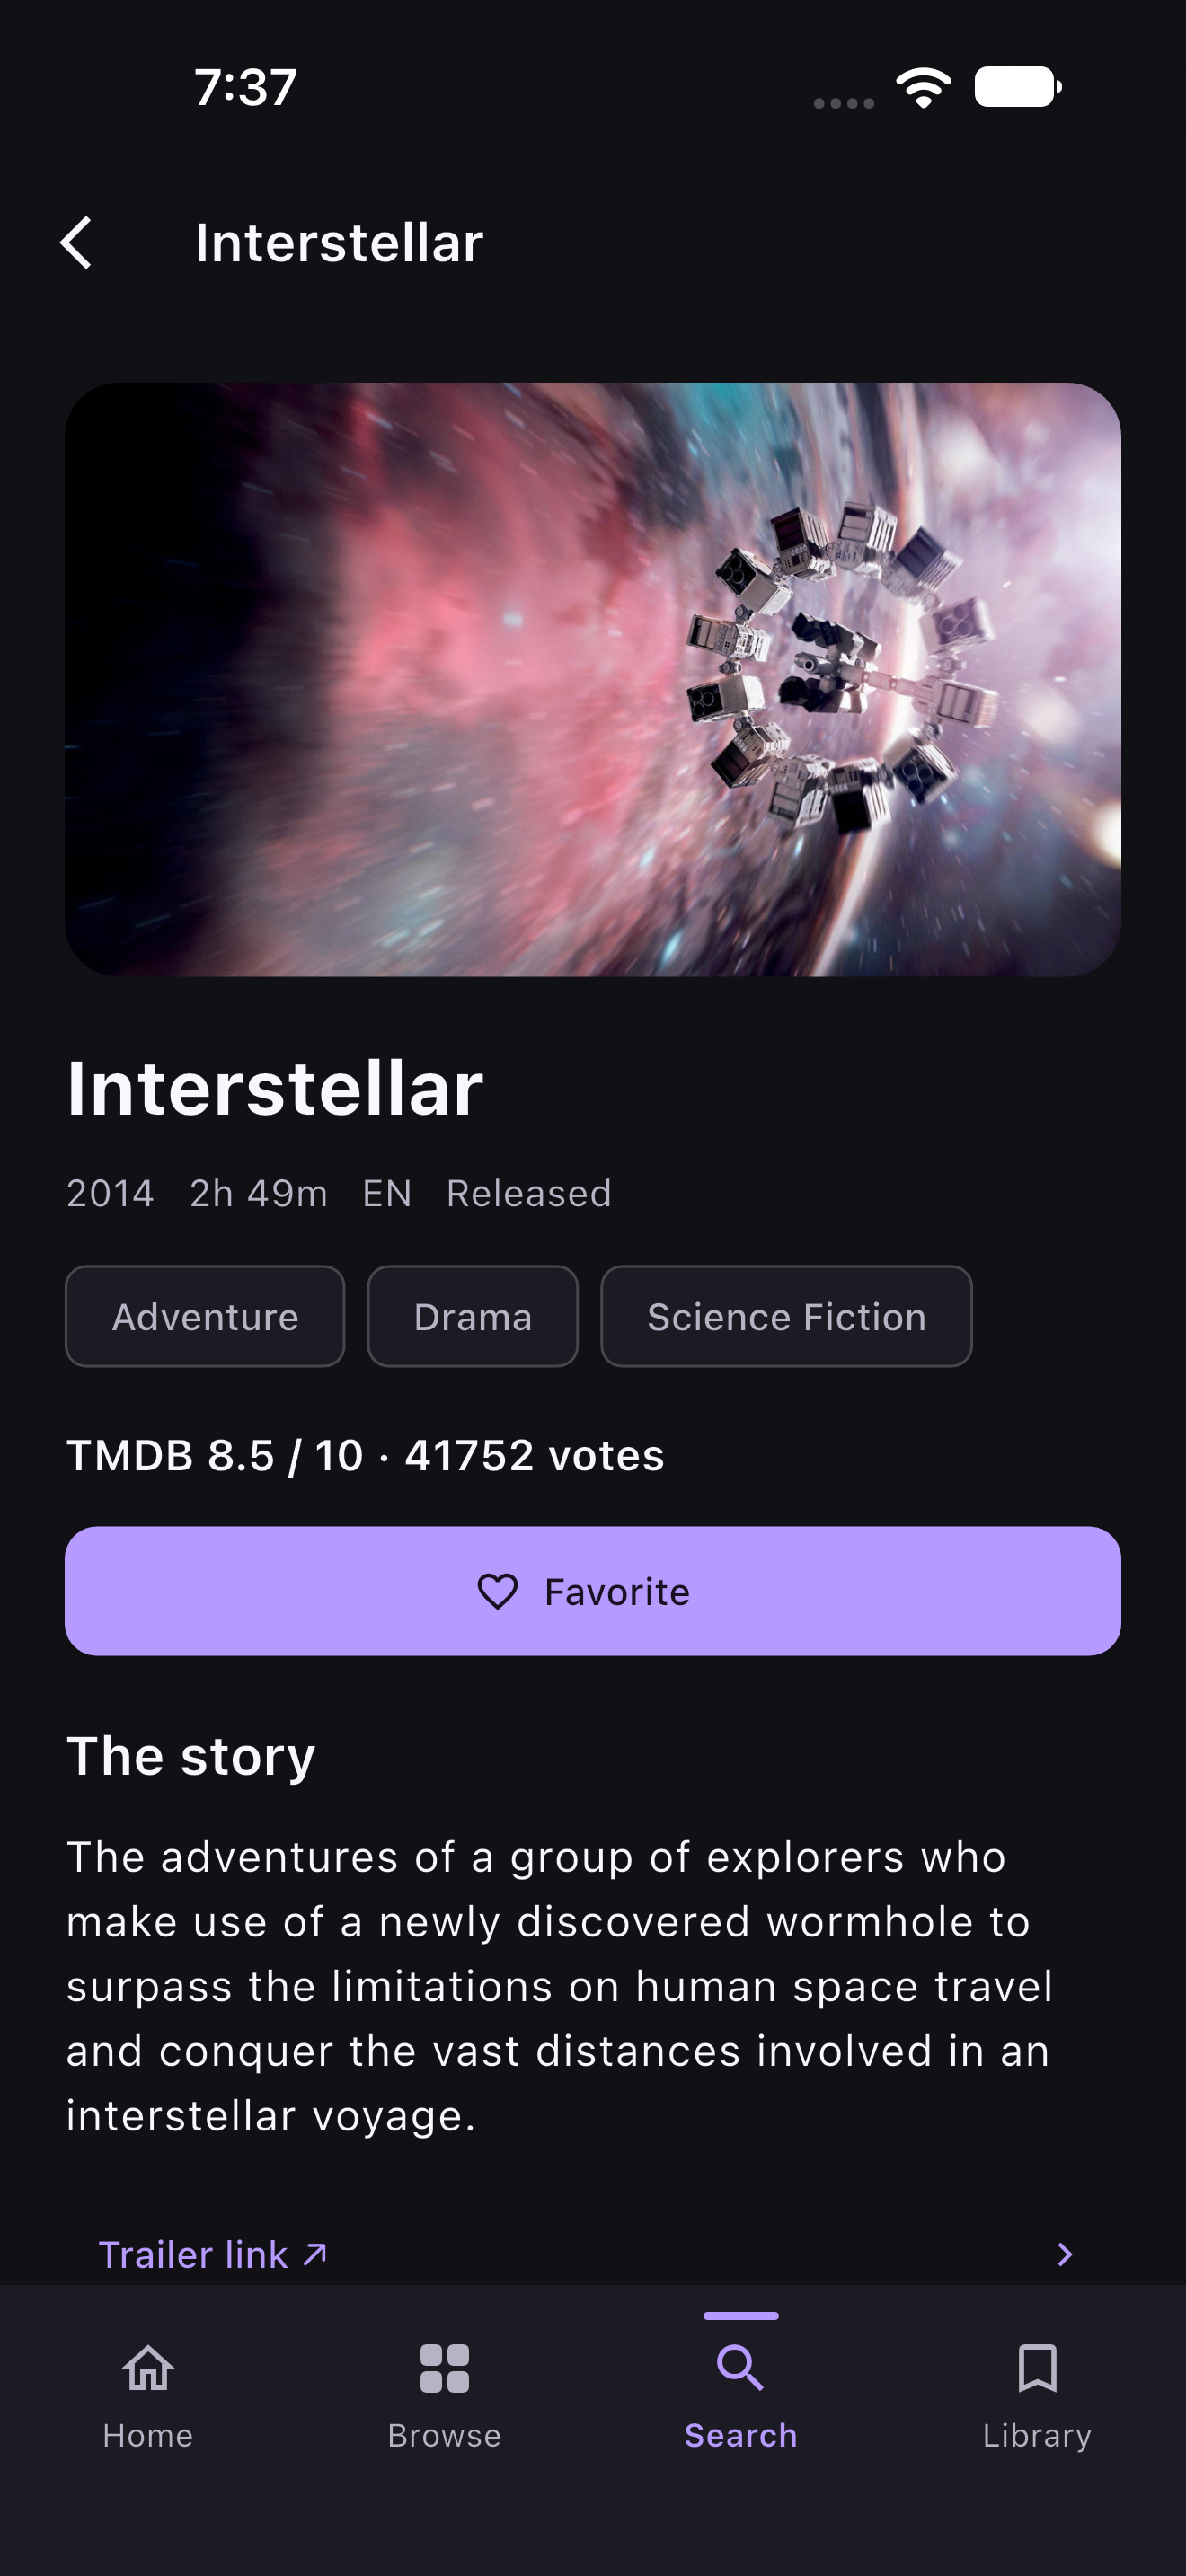

In [7]:
import json
import os
import shutil
import socket
import subprocess
import tempfile
import time
import urllib.error
import urllib.request
from appium import webdriver
from appium.options.ios import XCUITestOptions
from appium.webdriver.client_config import AppiumClientConfig
from selenium.webdriver.common.proxy import Proxy
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET

operations_observation, operations_inspection = None, None

if not all(name in globals() for name in ("server_dir", "node_bin", "appium_executable", "ios_options", "observe_ui", "inspect_element")):
    raise RuntimeError("Run this notebook's setup cells first (and its definitions cell where present).")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime.")
if os.environ.get("APPIUM_HOME") != str(server_dir / ".tools" / "appium"):
    raise RuntimeError("Reactivate the project-local Appium home.")
if ios_options.no_reset is not True or ios_options.full_reset is not False:
    raise ValueError("Rerun this notebook's profile/options setup cells to restore this exercise's explicit reset policy.")

# Revalidate the profile/options and installed target immediately before this run.
if "selected_profile" not in globals():
    raise RuntimeError("Run this notebook's profile setup cell first.")
if selected_profile.get("platform") != "ios" or selected_profile.get("execution_provider") != "local":
    raise ValueError("This example requires the local iOS profile.")
if ios_options.udid != selected_profile["simulator_udid"] or ios_options.bundle_id != selected_profile["app_bundle_id"]:
    raise ValueError("The profile/options differ; rerun this notebook's profile/options setup cells.")
devices = json.loads(subprocess.check_output(
    ["xcrun", "simctl", "list", "devices", "--json"], text=True, timeout=20,
))
targets = [d for entries in devices["devices"].values() for d in entries
           if d["udid"] == ios_options.udid]
if len(targets) != 1 or targets[0]["state"] != "Booted" or not targets[0].get("isAvailable"):
    raise RuntimeError("The selected Simulator must be available and booted.")
app_path = subprocess.check_output(
    ["xcrun", "simctl", "get_app_container", ios_options.udid, ios_options.bundle_id, "app"],
    text=True, timeout=20,
).strip()
if not Path(app_path).is_dir():
    raise RuntimeError("The installed Movies container could not be verified.")

host, port, wda_port = "127.0.0.1", 4723, 8100
with socket.socket() as probe:
    probe.bind((host, port))  # Leave an existing Appium server alone.

connection_options = XCUITestOptions().load_capabilities(ios_options.to_capabilities())
connection_options.set_capability("appium:wdaBindingIP", host)
connection_options.set_capability("appium:wdaLocalPort", wda_port)
server_url = f"http://{host}:{port}"
client_config = AppiumClientConfig(
    remote_server_addr=server_url, timeout=300,
    proxy=Proxy({"proxyType": "direct"}),
    init_args_for_pool_manager={"init_args_for_pool_manager": {"retries": 0}},
)
expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
log_dir = server_dir / ".tools" / "logs"
log_dir.mkdir(parents=True, exist_ok=True)
with tempfile.NamedTemporaryFile(mode="w", prefix="operations-config-", suffix=".json",
                                 dir=log_dir, delete=False) as config_file:
    json.dump({"server": {}}, config_file)
status_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
session_driver, session_process, session_result = None, None, None
with tempfile.NamedTemporaryFile(mode="w", prefix="operations-check-", suffix=".log",
                                 dir=log_dir, delete=False) as session_log:
    print("Server/session log:", session_log.name, flush=True)
    try:
        session_process = subprocess.Popen(
            [str(node_bin / "node"), str(appium_executable), "--config", config_file.name,
             "--address", host, "--port", str(port), "--log-no-colors", "--log-timestamp"],
            cwd=server_dir, env=os.environ.copy(), stdout=session_log, stderr=subprocess.STDOUT,
        )
        print("Owned Appium PID:", session_process.pid, flush=True)
        deadline = time.monotonic() + 30
        while time.monotonic() < deadline:
            if session_process.poll() is not None:
                raise RuntimeError(f"Appium exited early; inspect {session_log.name}")
            try:
                with status_opener.open(server_url + "/status", timeout=2) as response:
                    server_status = json.load(response)["value"]
                break
            except urllib.error.URLError:
                time.sleep(0.25)
        else:
            raise TimeoutError(f"Appium startup timed out; inspect {session_log.name}")
        if server_status.get("ready") is not True or server_status.get("build", {}).get("version") != expected_version:
            raise RuntimeError("Appium did not return the expected readiness/version.")
        if session_process.poll() is not None:
            raise RuntimeError("The owned server stopped before session creation.")
        print("Requesting XCUITest session; first WDA setup may take time...", flush=True)
        session_driver = webdriver.Remote(
            command_executor=server_url, options=connection_options, client_config=client_config,
        )
        if not session_driver.session_id:
            raise RuntimeError("The client did not receive a session ID.")
        session_result = {"session_id": session_driver.session_id,
                          "returned_capabilities": session_driver.capabilities}
        client_config.timeout = 20
        artifact_root = server_dir / ".tools" / "observations"
        operations_observation = observe_ui(session_driver, artifact_root)
        operations_inspection = inspect_element(session_driver, "movies.shell.tab.search")
        print("Observation receipt:", json.dumps(operations_observation, indent=2), flush=True)
        print("Inspection receipt:", json.dumps(operations_inspection, indent=2), flush=True)
        if operations_observation["status"] != "complete" or not operations_observation["receipt_persisted"]:
            raise RuntimeError("The extracted observation operation did not save complete evidence.")
        if operations_inspection["status"] != "resolved":
            raise RuntimeError("The chosen example element was not uniquely resolved.")

    finally:
        try:
            if session_driver is not None:
                client_config.timeout = 20  # Bound cleanup requests separately from startup.
                session_driver.quit()
                print("Automation session closed.", flush=True)
        finally:
            if session_process is not None:
                if session_process.poll() is None:
                    session_process.terminate()
                    try:
                        session_process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        session_process.kill()
                        session_process.wait(timeout=5)
                print("Owned Appium process stopped:", session_process.poll() is not None, flush=True)

from IPython.display import Image, display

# Offline display after session/server cleanup; no closed-driver calls.
display(Image(filename=operations_observation["artifacts"]["screenshot"]["path"], width=300))


### Read the operation receipts, then pause

The functions now separate **domain-neutral iOS execution primitives** from Movies-specific selectors and assertions. The live check establishes that capture/inspection work through the current Appium session; it does not exercise the new tap wrapper on the device or verify the movie again.

`inspect_element` can resolve an element that is disabled or hidden; its attributes describe that state. `tap_element` separately rejects such a target, a missing/ambiguous locator, or a native-type mismatch. It persists dispatch intent before a single click call, and reports response acknowledgment separately from the action's effect.

Operational errors are returned as structured data. A future executor must inspect those statuses rather than assume that a returned dictionary means success. In particular, an uncertain dispatch must not be automatically repeated. The caller remains responsible for fresh observations and later effect/assertion verification, plus session cleanup.

**Pause here:** the next small step can wrap one of these trusted, session-bound functions as a LangChain tool and inspect its input/output contract. That will be separate from creating an autonomous executor or exposing an MCP server.


**Recorded live verification:** `2026-11-03T12:42:19.928046+00:00` (UTC). `observe_ui` saved valid XML and PNG with a persisted receipt. `inspect_element` resolved one native Search-tab button and returned JSON-compatible attributes. The Appium HTTP log confirms **zero element click/type/clear/action-sequence commands** during this live check, followed by successful session deletion and server exit code `0`. The screenshot above is the actual retained app state captured by the extracted operation.

Observation receipt: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/observe-4twkb1jp/manifest.json`. The XML and PNG are alongside it under ignored `.tools/observations/`.

**Separate offline validation:** 8 controlled-driver checks covered missing/ambiguous locators, hidden/disabled/type-mismatched targets, acknowledgment without an effect-verification claim, uncertain dispatch without retry, intent-save failure preventing a click, partial capture retaining PNG, and final-recording failure retaining the valid pending intent. The recording-failure regression was reproduced before the atomic-update fix and passed afterward. These are helper checks, not real UI actions or application test verdicts. The new tap wrapper has not been dispatched against the live app in this module.


[Index](README.md) · [Previous lesson](15_movie_details_assertions.ipynb) · [Next lesson](17_langchain_observation_tool.ipynb)